In [64]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make NumPy printouts easier to read.
np.set_printoptions(precision=3, suppress=True)

In [65]:
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.16.1


In [66]:
raw_dataset = pd.read_csv('./output_file.csv')

In [67]:
raw_dataset.head()

,w1,w2,w3,wPL,range
0,0.19,0.63,0.94,0.000029,168.577083
1,0.43,0.69,0.95,0.000073,193.161944
2,0.62,0.12,0.12,0.000062,125.559007
3,0.53,0.65,0.41,0.000032,98.348028
4,0.41,0.44,0.18,0.000074,134.261982


In [68]:
dataset = raw_dataset.copy()
dataset.tail()

,w1,w2,w3,wPL,range
697,0.48,0.68,0.21,0.000028,147.791200
698,0.39,0.76,0.62,0.000048,168.577083
699,0.92,0.35,0.22,0.000075,168.577083
700,0.95,0.54,0.54,0.000073,205.729167
701,0.22,0.13,0.31,0.000041,167.661833


In [69]:
dataset.isna().sum()

w1       0
w2       0
w3       0
wPL      0
range    0
dtype: int64

In [70]:
dataset = dataset.dropna()

In [71]:
dataset.tail()

,w1,w2,w3,wPL,range
697,0.48,0.68,0.21,0.000028,147.791200
698,0.39,0.76,0.62,0.000048,168.577083
699,0.92,0.35,0.22,0.000075,168.577083
700,0.95,0.54,0.54,0.000073,205.729167
701,0.22,0.13,0.31,0.000041,167.661833


In [72]:
train_dataset = dataset.sample(frac=0.8, random_state=0)
test_dataset = dataset.drop(train_dataset.index)

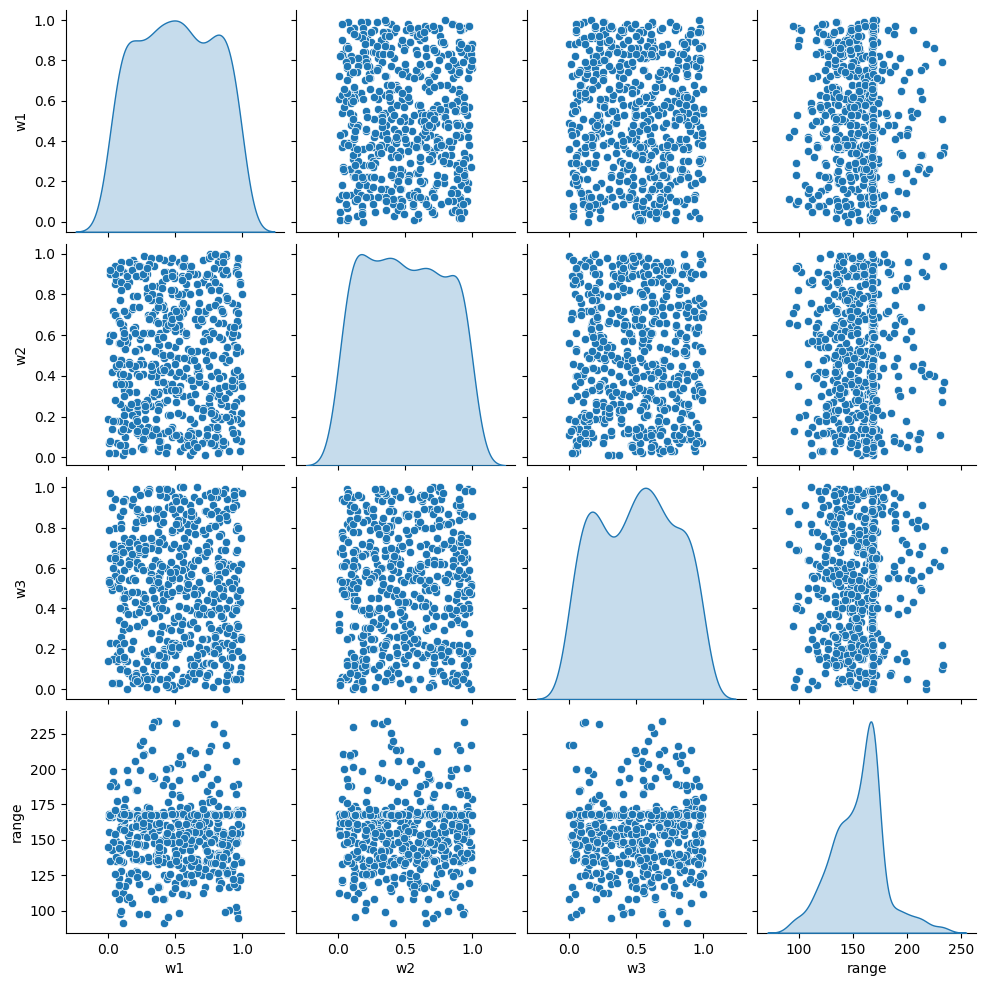

In [73]:
sns.pairplot(train_dataset[['w1', 'w2', 'w3', 'range']], diag_kind='kde')

In [74]:
train_dataset.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
w1,562.0,0.508577,0.283068,0.000000,0.262500,0.510000,0.750000,1.000000
w2,562.0,0.498363,0.289417,0.010000,0.242500,0.490000,0.740000,1.000000
w3,562.0,0.499893,0.286812,0.000000,0.230000,0.510000,0.730000,1.000000
wPL,562.0,0.000051,0.000028,0.000000,0.000027,0.000052,0.000075,0.000100
range,562.0,155.317355,24.143598,91.597056,138.095356,158.616256,168.577083,233.932222


In [75]:
train_dataset.head()

,w1,w2,w3,wPL,range
538,0.61,0.01,0.32,0.000068,168.577083
476,0.30,0.70,0.38,0.000052,166.104641
547,0.64,0.17,0.05,0.000075,137.112085
573,0.28,0.19,0.16,0.000067,146.385260
517,0.84,0.20,0.30,0.000045,167.661833


In [76]:
train_features = train_dataset.copy()
test_features = test_dataset.copy()

train_labels = train_features.pop('range')
test_labels = test_features.pop('range')

In [77]:
train_features.head()

,w1,w2,w3,wPL
538,0.61,0.01,0.32,0.000068
476,0.30,0.70,0.38,0.000052
547,0.64,0.17,0.05,0.000075
573,0.28,0.19,0.16,0.000067
517,0.84,0.20,0.30,0.000045


In [78]:
train_labels.head()

538    168.577083
476    166.104641
547    137.112085
573    146.385260
517    167.661833
Name: range, dtype: float64

In [79]:
train_dataset.describe().transpose()[['mean', 'std']]

,mean,std
w1,0.508577,0.283068
w2,0.498363,0.289417
w3,0.499893,0.286812
wPL,0.000051,0.000028
range,155.317355,24.143598


In [80]:
pd.DataFrame(train_dataset)

,w1,w2,w3,wPL,range
538,0.61,0.01,0.32,0.000068,168.577083
476,0.30,0.70,0.38,0.000052,166.104641
547,0.64,0.17,0.05,0.000075,137.112085
573,0.28,0.19,0.16,0.000067,146.385260
517,0.84,0.20,0.30,0.000045,167.661833
...,...,...,...,...,...
464,0.32,0.45,0.75,0.000079,167.661833
25,0.66,0.24,0.30,0.000034,167.661833
110,0.12,0.72,0.16,0.000083,168.577083
149,0.93,0.12,0.90,0.000038,122.428833


In [81]:
normalizer = tf.keras.layers.Normalization(axis=-1)

In [82]:
normalizer.adapt(np.array(train_features))

In [83]:
print(normalizer.mean.numpy())

[[0.509 0.498 0.5   0.   ]]


In [84]:
first = np.array(train_features[:1])

with np.printoptions(precision=2, suppress=True):
  print('First example:', first)
  print()
  print('Normalized:', normalizer(first).numpy())

First example: [[0.61 0.01 0.32 0.  ]]

Normalized: [[ 0.36 -1.69 -0.63  0.6 ]]


In [85]:
w1 = np.array(train_features['w1'])

w1_normalizer = layers.Normalization(input_shape=[1,], axis=None)

w1_normalizer.adapt(w1)


/Users/danish/miniforge3/lib/python3.10/site-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [86]:
w1_model = tf.keras.Sequential([
    w1_normalizer,
    layers.Dense(units=1)
])

w1_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization) │ (None, 1)              │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5 (24.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 3 (16.00 B)

In [87]:
w1_model.predict(w1[:10])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


array([[ 0.576],
       [-1.184],
       [ 0.746],
       [-1.298],
       [ 1.882],
       [-1.354],
       [-0.73 ],
       [-0.276],
       [-2.036],
       [ 0.008]], dtype=float32)

In [89]:
w1_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss='mean_absolute_error')

In [96]:
%%time
history = w1_model.fit(
    train_features['w1'],
    train_labels,
    epochs=100,
    # suppress logging
    verbose=0,
    # Calculate validation results on 20% of the training data
    validation_split = 0.2)

CPU times: user 2.09 s, sys: 294 ms, total: 2.38 s
Wall time: 2.09 s


In [91]:
hist = pd.DataFrame(history.history)
hist['epoch'] = history.epoch
hist.tail()

,loss,val_loss,epoch
95,24.281796,26.861086,95
96,23.848061,26.463737,96
97,23.474985,26.099232,97
98,23.116804,25.633543,98
99,22.733170,25.194401,99


In [94]:
def plot_loss(history):
  plt.plot(history.history['loss'], label='loss')
  plt.plot(history.history['val_loss'], label='val_loss')
  plt.ylim([0, 10])
  plt.xlabel('Epoch')
  plt.ylabel('Error [range]')
  plt.legend()
  plt.grid(True)

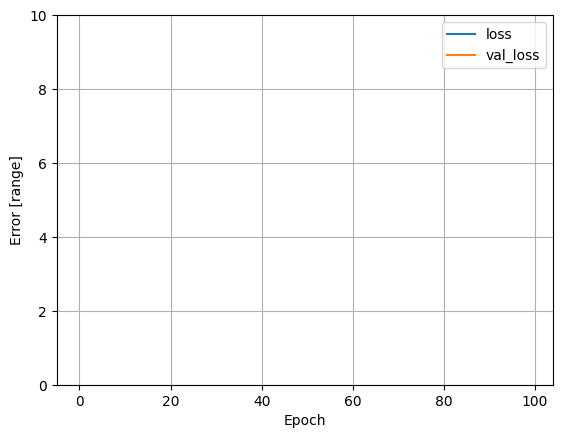

In [95]:
plot_loss(history)

In [97]:
test_results = {}

test_results['w1_model'] = w1_model.evaluate(
    test_features['w1'],
    test_labels, verbose=0)



In [98]:
x = tf.linspace(0.0, 250, 251)

y = w1_model.predict(x)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


In [109]:
def plot_model(x, y):
    plt.scatter(train_features ['w1'], train_labels, label='Data')
    plt.plot(x, y, color='k', label='Predictions')
    plt.xlabel('w1')
    plt.ylabel('range')
    plt.legend()
  

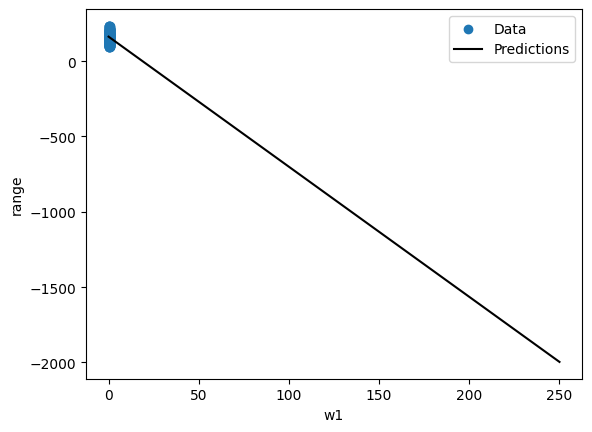

In [111]:
plot_model(x,y)

In [101]:
linear_model = tf.keras.Sequential([
    normalizer,
    layers.Dense(units=1)
])

In [102]:
linear_model.predict(train_features[:10])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


array([[ 0.752],
       [-0.47 ],
       [-0.764],
       [ 0.6  ],
       [-0.505],
       [-1.99 ],
       [ 0.479],
       [-1.154],
       [-1.214],
       [ 1.28 ]], dtype=float32)

In [103]:
linear_model.layers[1].kernel

<KerasVariable shape=(4, 1), dtype=float32, path=sequential_4/dense_10/kernel>

In [104]:
linear_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss='mean_absolute_error')

In [105]:
%%time
history = linear_model.fit(
    train_features,
    train_labels,
    epochs=100,
    # Suppress logging.
    verbose=0,
    # Calculate validation results on 20% of the training data.
    validation_split = 0.2)

CPU times: user 2.26 s, sys: 325 ms, total: 2.58 s
Wall time: 2.23 s


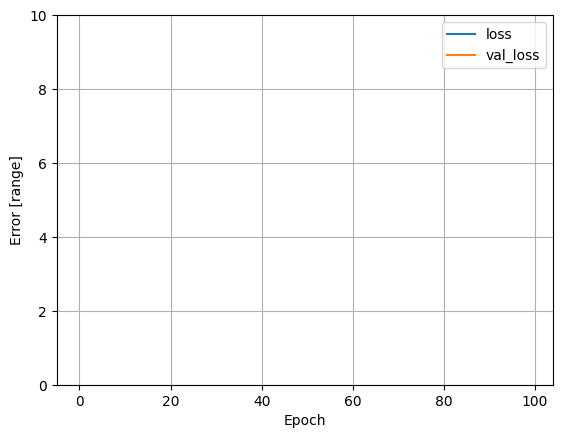

In [112]:
plot_loss(history)

In [107]:
test_results['linear_model'] = linear_model.evaluate(
    test_features, test_labels, verbose=0)

In [124]:
def build_and_compile_model(norm):
  model = keras.Sequential([
      norm,
      layers.Dense(64, activation='relu'),
      layers.Dense(64, activation='relu'),
      layers.Dense(1)
  ])

  model.compile(loss='mean_absolute_error',
                optimizer=tf.keras.optimizers.Adam(0.001))
  return model

In [114]:
dnn_model = build_and_compile_model(normalizer)


In [115]:
dnn_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (10, 4)                │             9 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9 (40.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 9 (40.00 B)

In [121]:
%%time
history = dnn_model.fit(
    train_features,
    train_labels,
    validation_split=0.2,
    verbose=0,
    epochs=100)


CPU times: user 2.23 s, sys: 292 ms, total: 2.52 s
Wall time: 2.17 s


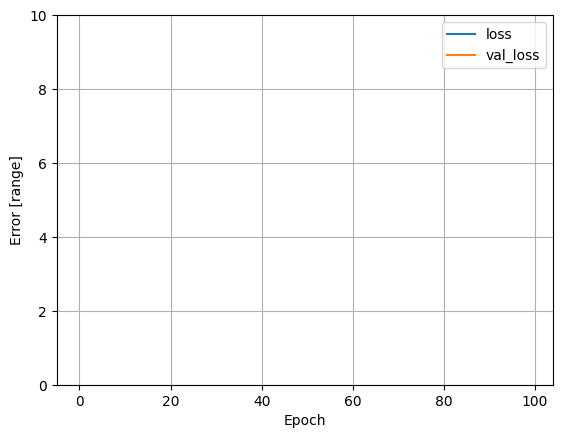

In [122]:
plot_loss(history)

In [123]:
x = tf.linspace(0.0, 250, 251)

y = dnn_model.predict(x)

ValueError: Exception encountered when calling Sequential.call().

[1mInvalid input shape for input Tensor("data:0", shape=(32,), dtype=float32). Expected shape (None, 4), but input has incompatible shape (32,)[0m

Arguments received by Sequential.call():
  • inputs=tf.Tensor(shape=(32,), dtype=float32)
  • training=False
  • mask=None